In [1]:
from mylib.statistic_test import *

code_id = "0884 - Pretraining Heterogeneity"
loc = join(figpath, "Dsp", code_id)
os.makedirs(loc, exist_ok=True)

d:\Softwares\Anaconda2025\envs\maze\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


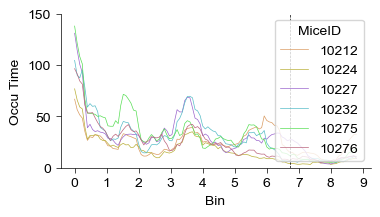

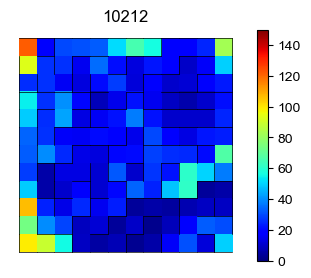

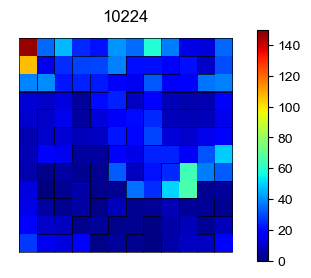

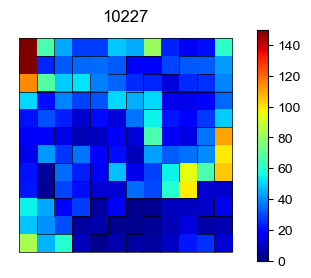

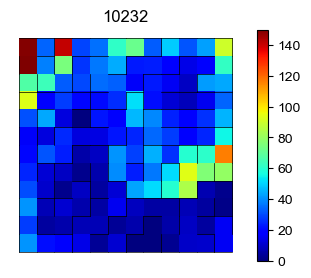

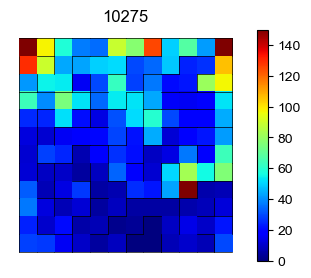

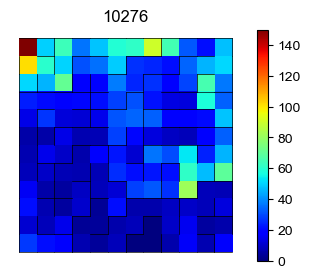

In [16]:
def get_occu_time(trace):
    nodes = spike_nodes_transform(trace['correct_nodes'], 12)
    dt = np.diff(trace['correct_time'])
    dt = np.append(dt, np.median(dt))
    dt[dt > 100] = 100
    
    occu_time = scipy.stats.binned_statistic(
        nodes,
        dt,
        statistic='sum',
        bins=144,
        range=(0, 144+1e-3)
    )[0]
    
    return occu_time
    
    
paths = [
    r"D:\Data\Cross_maze\10212\20230426\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10224\20230806\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10227\20230806\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10232\20240829\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10275\20260415\session 2\trace_behav.pkl",
    r"D:\Data\Cross_maze\10276\20260414\session 2\trace_behav.pkl",
]

if exists(join(figdata, f"{code_id} [occu time].pkl")) == False:
    OT = {
        "MiceID": [],
        "Occu Time": [],
        "Bin": []
    }
    for mouse, pt in zip(["10212", "10224", "10227", "10232", "10275", "10276"], paths):
        with open(pt, 'rb') as f:
            trace = pickle.load(f)
        occu_time = get_occu_time(trace)[CP_DSP1[0]-1]/1000
        occu_time = np.convolve(occu_time, np.ones(7), mode='same') / np.convolve(np.ones_like(occu_time), np.ones(7), mode='same')
        
        OT["MiceID"].append([mouse]*len(occu_time))
        OT["Occu Time"].append(occu_time)
        OT["Bin"].append(np.arange(CP_DSP1[0].shape[0]))
        
    for k in OT.keys():
        OT[k] = np.concatenate(OT[k])
        
    with open(join(figdata, f"{code_id} [occu time].pkl"), 'wb') as f:
        pickle.dump(OT, f)
        
    OTD = pd.DataFrame(OT)
    OTD.to_excel(join(figdata, f"{code_id} [occu time].xlsx"), index=False)
    print(len(OTD))
else:
    with open(join(figdata, f"{code_id} [occu time].pkl"), 'rb') as f:
        OT = pickle.load(f)
        
fig = plt.figure(figsize=(4, 2))
ax = Clear_Axes(plt.axes(), close_spines=["top", "right"], ifxticks=True, ifyticks=True)
sns.lineplot(
    x="Bin",
    y="Occu Time",
    hue="MiceID",
    linewidth=0.5,
    palette=MicePaletteDSP,
    data = OT,
    ax=ax
)
idx = np.where(CP_DSPs[1][0] == CP_DSPs[1][3][0])[0][0]
ax.axvline(idx, color='k', linestyle='--', linewidth=0.5)
ax.set_xticks(np.linspace(0, 112.5, 10), np.linspace(0, 9, 10).astype(int))
ax.set_ylim(0, 150)
plt.savefig(join(loc, "Occu Time.svg"), dpi=300)
plt.savefig(join(loc, "Occu Time.png"), dpi=300)
plt.show()

for mouse, pt in zip(["10212", "10224", "10227", "10232", "10275", "10276"], paths):
    with open(pt, 'rb') as f:
        trace = pickle.load(f)
    occu_time = get_occu_time(trace)/1000
    
    fig = plt.figure(figsize=(4, 3))
    ax = Clear_Axes(plt.axes())
    im = ax.imshow(occu_time.reshape(12, 12),cmap='jet', vmin=0, vmax=150)
    cbar = plt.colorbar(im, ax=ax)
    DrawMazeProfile(maze_type=1, ax=ax, color='k', linewidth=0.5, nx=12)
    ax.invert_yaxis()
    ax.set_aspect('equal'),
    ax.set_title(mouse)
    plt.savefig(join(loc, f"Occu Time {mouse}.svg"), dpi=300)
    plt.savefig(join(loc, f"Occu Time {mouse}.png"), dpi=300)
    plt.show()

# Single to Bistable system occurs during retrieval

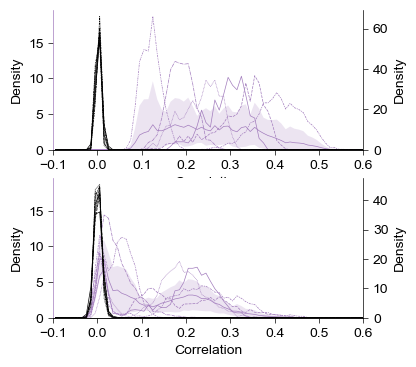

In [75]:
from mazepy.datastruc.neuact import SpikeTrain
from mazepy.datastruc.variables import VariableBin
from sklearn.decomposition import PCA

paths_lastsession = [
    r"D:\Data\Cross_maze\10212\20230521\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10224\20230930\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10227\20230930\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10232\20241019\session 2\trace_sim.pkl",
    r"D:\Data\Cross_maze\10275\20260428\session 2\trace.pkl",
    r"D:\Data\Cross_maze\10276\20260428\session 2\trace.pkl",
]


def get_lapwise_ratemap(trace: dict, is_cutted: bool = True):    
    maze_type = trace['maze_type']
    try:
        beg_time, end_time = trace['lap beg time'], trace['lap end time']
    except KeyError:
        beg_time, end_time = trace['correct_time'][trace['lap_begin_index']], trace['correct_time'][trace['lap_end_index']]
    beg_idx = np.array([np.where(trace['correct_time'] >= beg_time[i])[0][0] for i in range(beg_time.shape[0])])
    routes = classify_lap(spike_nodes_transform(trace['correct_nodes'], 12), beg_idx, maze_type)
    smoothed_map = np.zeros((trace['n_neuron'], 144, beg_idx.shape[0]), dtype = np.float64)
    
    for i in range(beg_idx.shape[0]):
        
        try:
            assert trace['Spikes_original'].shape[1] == trace['spike_nodes_original'].shape[0] == trace['ms_time'].shape[0]
            spike_idx = np.where(
                (trace['ms_time'] >= beg_time[i]) & (trace['ms_time'] <= end_time[i]) &
                (np.isnan(trace['spike_nodes_original']) == False)
            )[0]
            
            spike_nodes = spike_nodes_transform(trace['spike_nodes_original'][spike_idx].astype(np.int64), 12)-1
            Spikes = trace['Spikes_original'][:, spike_idx]
            ms_time = trace['ms_time'][spike_idx]
        except:
            spike_idx = np.where(
                (trace['ms_time_behav'] >= beg_time[i]) & (trace['ms_time_behav'] <= end_time[i]) &
                (np.isnan(trace['spike_nodes']) == False)
            )[0]
            spike_nodes = spike_nodes_transform(trace['spike_nodes'][spike_idx].astype(np.int64), 12)-1
            Spikes = trace['Spikes'][:, spike_idx]
            ms_time = trace['ms_time_behav'][spike_idx]
        
        spike_train = SpikeTrain(
            activity=Spikes,
            time=ms_time,
            variable=VariableBin(spike_nodes)
        )
        
        rate_map = spike_train.calc_tuning_curve(144, t_interv_limits=100)
        smoothed_map[:, :, i] = rate_map.to_array() #@ trace['Ms'].T
    
    if is_cutted:
        bins = CP_DSPs[maze_type][3]-1
        smoothed_map = smoothed_map[:, bins, :]

    X = np.transpose(smoothed_map, (2, 1, 0))
    return X, routes

paths_first_session = [
    f2['Trace File'][np.where(f2['MiceID'] == mouse)[0][0]] for mouse in [10212, 10224, 10227, 10232, 10275, 10276]
]
if exists(join(figdata, f"{code_id} [trialwise corr].pkl")) == False:
    Corr = {
        "MiceID": [],
        "Correlation": [],
        "Density": [],
        "Type": [],
        "Session": []
    }
    for n, mouse in tqdm(enumerate([10212, 10224, 10227, 10232, 10275, 10276])):
        for s, pt in zip(["Pre", "Post"], [paths_lastsession[n], paths_first_session[n]]):
            with open(pt, 'rb') as f:
                trace = pickle.load(f)
                
            if s == "Pre":
                X = get_lapwise_ratemap(trace, is_cutted=False)[0][:, CP_DSP1[0]-1, :]
                X_shuf = X.copy()
                for j in range(X.shape[0]):
                    X_shuf[j, :, :] = X_shuf[j, :, np.random.permutation(X_shuf.shape[2])].T
                X = X.reshape(X.shape[0], -1)
                X_shuf = X_shuf.reshape(X_shuf.shape[0], -1)
                corr = np.corrcoef(X)
                corr = corr[np.triu_indices(corr.shape[0], k=1)]
                corr_shuf = np.corrcoef(X_shuf)
                corr_shuf = corr_shuf[np.triu_indices(corr_shuf.shape[0], k=1)]   
                         
            elif s == "Post":
                X, routes = get_lapwise_ratemap(trace, is_cutted=False)
                X_shuf = X.copy()
                for j in range(X.shape[0]):
                    X_shuf[j, :, :] = X_shuf[j, :, np.random.permutation(X_shuf.shape[2])].T
                
                corr = np.zeros((X.shape[0], X.shape[0]), dtype=np.float64)
                corr_shuf = np.zeros((X.shape[0], X.shape[0]), dtype=np.float64)
                for i in range(7):
                    for j in range(7):
                        idx_i = np.where(routes == i)[0]
                        idx_j = np.where(routes == j)[0]
                        commbined = np.unique(np.concatenate([idx_i, idx_j]))
                        intersected_bins = np.intersect1d(CP_DSP1[i], CP_DSP1[j])-1
                        X_ij = X[:, intersected_bins, :][commbined, :, :]
                        X_ij_shuf = X_shuf[:, intersected_bins, :][commbined, :, :]
                        corr[np.ix_(commbined, commbined)] = np.corrcoef(X_ij.reshape(X_ij.shape[0], -1))
                        corr_shuf[np.ix_(commbined, commbined)] = np.corrcoef(X_ij_shuf.reshape(X_ij_shuf.shape[0], -1))
                        
                corr = corr[np.triu_indices(corr.shape[0], k=1)]
                corr_shuf = corr_shuf[np.triu_indices(corr_shuf.shape[0], k=1)]

            
            x = np.linspace(-0.1, 1, 111)
            x = (x[1:]+x[:-1])/2
            hist = np.histogram(corr, bins=110, range=(-0.1, 1), density=True)[0]
            hist_shuf = np.histogram(corr_shuf, bins=110, range=(-0.1, 1), density=True)[0]
            
            Corr["MiceID"].append([mouse]*len(x)*2)
            Corr["Correlation"].append(np.concatenate([x, x]))
            Corr["Density"].append(np.concatenate([hist, hist_shuf]))
            Corr["Type"].append(np.concatenate([np.repeat("Data", len(hist)), np.repeat("Shuffled", len(hist_shuf))]))
            Corr["Session"].append([s]*len(hist)*2)
            
    for k in Corr.keys():
        Corr[k] = np.concatenate(Corr[k])
        
    with open(join(figdata, f"{code_id} [trialwise corr].pkl"), 'wb') as f:
        pickle.dump(Corr, f)
        
    CorrD = pd.DataFrame(Corr)
    CorrD.to_excel(join(figdata, f"{code_id} [trialwise corr].xlsx"), index=False)
    print(len(CorrD))
else:
    with open(join(figdata, f"{code_id} [trialwise corr].pkl"), 'rb') as f:
        Corr = pickle.load(f)

Corr['Density'][Corr['Density'] <= 1e-8] = 1e-8
fig, axes = plt.subplots(2, 1, figsize=(4, 4), sharey=True)
ax0 = Clear_Axes(axes[0], close_spines=["top", "right"], ifxticks=True, ifyticks=True)
ax1 = Clear_Axes(axes[1], close_spines=["top", "right"], ifxticks=True, ifyticks=True)
subdata_pre_data = SubDict(Corr, Corr.keys(), np.where((Corr['Session'] == "Pre")&(Corr['Type'] == "Data"))[0])
subdata_pre_shuf = SubDict(Corr, Corr.keys(), np.where((Corr['Session'] == "Pre")&(Corr['Type'] == "Shuffled"))[0])
subdata_post_data = SubDict(Corr, Corr.keys(), np.where((Corr['Session'] == "Post")&(Corr['Type'] == "Data"))[0])
subdata_post_shuf = SubDict(Corr, Corr.keys(), np.where((Corr['Session'] == "Post")&(Corr['Type'] == "Shuffled"))[0])
axt0 = Clear_Axes(ax0.twinx(), close_spines=["top", "left"], ifxticks=True, ifyticks=True)
axt1 = Clear_Axes(ax1.twinx(), close_spines=["top", "left"], ifxticks=True, ifyticks=True)

for subdata, axin in zip([subdata_pre_data, subdata_pre_shuf, subdata_post_data, subdata_post_shuf], [ax0, axt0, ax1, axt1]):
    sns.lineplot(
        x="Correlation",
        y="Density",
        hue="Type",
        style='MiceID',
        linewidth=0.5,
        palette=['#a27cbd', 'k'],
        hue_order=["Data", "Shuffled"],
        data = subdata,
        ax=axin,
        legend=False
    )
    sns.lineplot(
        x="Correlation",
        y="Density",
        hue="Type",
        linewidth=0.5,
        palette=['#a27cbd', 'k'],
        hue_order=["Data", "Shuffled"],
        data = subdata,
        ax=axin,
        legend=False,
        err_kws={"edgecolor": None}
    )
    axin.set_xlim(-0.1, 0.6)
    axin.set_ylim(0, axin.get_ylim()[1])
    axin.spines["left"].set_color("#a27cbd")
    axin.spines["left"].set_linewidth(0.5)
    axin.spines["right"].set_color("k")
    axin.spines["right"].set_linewidth(0.5)
    
plt.savefig(join(loc, "Trialwise Correlation.svg"), dpi=300)
plt.savefig(join(loc, "Trialwise Correlation.png"), dpi=300)
plt.show()

(52, 52)


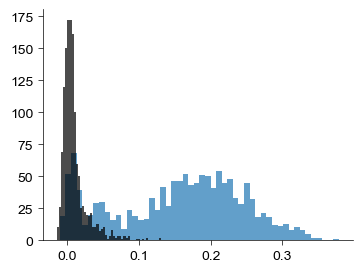

(89, 89)


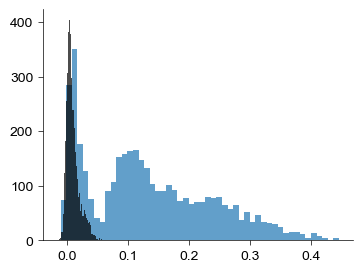

(68, 68)


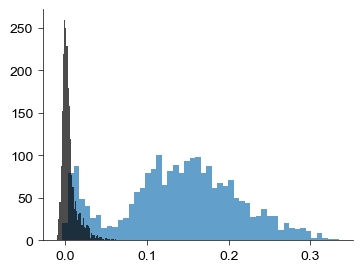

(99, 99)


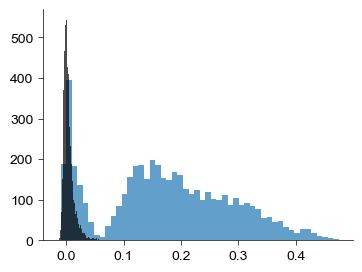

(104, 104)


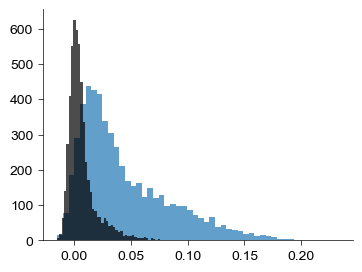

(103, 103)


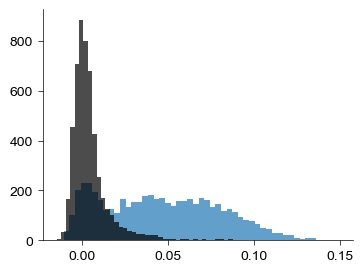

In [42]:
dsp_idx = [
    np.where(f2['MiceID'] == mouse)[0][0] for mouse in [10212, 10224, 10227, 10232, 10275, 10276]
]

for i in dsp_idx:
    with open(f2['Trace File'][i], 'rb') as f:
        trace = pickle.load(f)
        
    X = get_lapwise_ratemap(trace, is_cutted=False)[:, CP_DSP1[0]-1, :]
    X_shuf = X.copy()
    for j in range(X.shape[0]):
        X_shuf[j, :, :] = X_shuf[j, :, np.random.permutation(X_shuf.shape[2])].T
        
    X = X.reshape(X.shape[0], -1)
    X_shuf = X_shuf.reshape(X_shuf.shape[0], -1)
    corr = np.corrcoef(X)
    corr_shuf = np.corrcoef(X_shuf)
    
    print(corr.shape)
    fig = plt.figure(figsize=(4, 3))
    ax = Clear_Axes(plt.axes(), close_spines=["top", "right"], ifxticks=True, ifyticks=True)
    ax.hist(corr[np.triu_indices(corr.shape[0], k=1)], bins=50, alpha=0.7)
    ax.hist(corr_shuf[np.triu_indices(corr_shuf.shape[0], k=1)], bins=50, color='k', alpha=0.7)
    plt.show()